# 05 — Train the v4_srsh_aug Model and Predict on a New Dimer

This notebook trains the recommended **`v4_srsh_aug`** Random Forest on the
815 training structures (704 systematic + 111 Slater MD), evaluates it on the
held-out test sets, and shows how to predict $J$ for an arbitrary new dimer xyz.

The whole notebook runs in ~30 seconds. The model produced here is identical to
the one in `models/stage2_rf_v4_srsh_aug.pkl`.


## Setup

In [1]:
import sys, os
import numpy as np
import pandas as pd
import joblib
from scipy.stats import pearsonr
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

sys.path.insert(0, '../src')


## Step 1: Load the master dataset and define the 14-D feature vector

In [2]:
df = pd.read_csv('../data/master_dataset.csv')

GEOM_FEATURES = ['dz', 'dx', 'dy', 'cos_theta',
                 'cos_4phi', 'sin_4phi', 'cos_4psi', 'sin_4psi',
                 'd_lateral', 'cos_4alpha', 'sin_4alpha']

def make_v4_features(df):
    '''11 geometric features + S_12 + S_12^2 + log|S_12|.'''
    X = df[GEOM_FEATURES].values
    s12 = df['S12_srsh_cation'].values
    extra = np.column_stack([s12, s12**2, np.log10(np.abs(s12) + 1e-12)])
    return np.column_stack([X, extra])

V4_FEATURE_NAMES = GEOM_FEATURES + ['S12', 'S12_sq', 'log_abs_S12']
print(f'14-D feature vector: {V4_FEATURE_NAMES}')


14-D feature vector: ['dz', 'dx', 'dy', 'cos_theta', 'cos_4phi', 'sin_4phi', 'cos_4psi', 'sin_4psi', 'd_lateral', 'cos_4alpha', 'sin_4alpha', 'S12', 'S12_sq', 'log_abs_S12']


## Step 2: Define train / test splits

We use 477 (704 systematic train) + 88 (Slater train) = **565 training structures**
with `J >= 1e-4 eV` (significant coupling). Test: 120 (704 test) + 23 (Slater test)
= 143 held-out structures.

In [3]:
# Filter to significant coupling
sig_mask = df['J_cdft_eV'] >= 1e-4

train_mask = (df['split'] == 'train') & sig_mask & df['S12_srsh_cation'].notna()
test_mask  = (df['split'] == 'test')  & sig_mask & df['S12_srsh_cation'].notna()

X_train = make_v4_features(df[train_mask])
y_train = df[train_mask]['log10_J_cdft'].values

X_test = make_v4_features(df[test_mask])
y_test = df[test_mask]['log10_J_cdft'].values

print(f'Training set: {len(X_train)} structures from {df[train_mask]["dataset"].value_counts().to_dict()}')
print(f'Test set:     {len(X_test)} structures from {df[test_mask]["dataset"].value_counts().to_dict()}')


Training set: 540 structures from {'704_systematic': 477, 'slater_111_md': 63}
Test set:     141 structures from {'704_systematic': 120, 'slater_111_md': 21}


## Step 3: Train the Random Forest

Hyperparameters: 500 trees, `max_features=0.5`, `max_depth=20`,
`min_samples_leaf=1`. Selected by cross-validation in the original report;
re-running here for reproducibility.

In [4]:
RF_PARAMS = dict(n_estimators=500, max_features=0.5, max_depth=20,
                 min_samples_leaf=1, random_state=42, n_jobs=-1)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestRegressor(**RF_PARAMS))
])

import time; t0 = time.time()
pipe.fit(X_train, y_train)
print(f'Trained in {time.time()-t0:.1f}s')


Trained in 0.6s


## Step 4: Evaluate

In [5]:
y_pred = pipe.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r, _ = pearsonr(y_pred, y_test)
print(f'Test set ({len(y_test)} structures):')
print(f'  log10|J| MAE = {mae:.4f}')
print(f'  Pearson r    = {r:.4f}')

# 5-fold CV on training set
cv_scores = cross_val_score(pipe, X_train, y_train, cv=5,
                            scoring='neg_mean_absolute_error', n_jobs=-1)
print(f'\n5-fold CV log MAE: {-cv_scores.mean():.4f} ± {cv_scores.std():.4f}')


Test set (141 structures):
  log10|J| MAE = 0.2621
  Pearson r    = 0.8528



5-fold CV log MAE: 0.2468 ± 0.0839


## Step 5: Parity plot

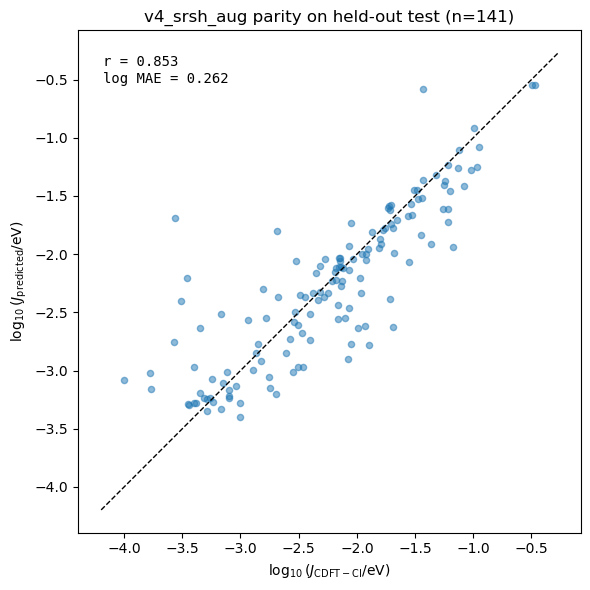

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred, alpha=0.5, s=20)
lo, hi = min(y_test.min(), y_pred.min()) - 0.2, max(y_test.max(), y_pred.max()) + 0.2
ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
ax.set_xlabel('$\\log_{10}(J_\\mathrm{CDFT-CI} / \\mathrm{eV})$')
ax.set_ylabel('$\\log_{10}(J_\\mathrm{predicted} / \\mathrm{eV})$')
ax.set_title(f'v4_srsh_aug parity on held-out test (n={len(y_test)})')
ax.set_aspect('equal')
ax.text(0.05, 0.95, f'r = {r:.3f}\nlog MAE = {mae:.3f}',
        transform=ax.transAxes, va='top', fontfamily='monospace')
plt.tight_layout()
plt.show()

## Step 6: Feature importances

In [7]:
importances = pipe.named_steps['rf'].feature_importances_
order = np.argsort(importances)[::-1]
print(f'{"feature":<14} {"importance":>10}')
for i in order:
    print(f'{V4_FEATURE_NAMES[i]:<14} {importances[i]:>10.4f}')


feature        importance
S12_sq             0.3152
log_abs_S12        0.3080
dz                 0.0758
cos_theta          0.0680
S12                0.0583
cos_4phi           0.0527
sin_4psi           0.0195
d_lateral          0.0163
sin_4phi           0.0162
cos_4psi           0.0150
sin_4alpha         0.0149
cos_4alpha         0.0141
dx                 0.0141
dy                 0.0120


## Step 7: Save the trained model

(Note: the production model `models/stage2_rf_v4_srsh_aug.pkl` is already
committed in the repo. This cell saves a fresh copy to `models/v4_srsh_aug_local.pkl`
to avoid overwriting the committed one.)

In [8]:
os.makedirs('../models', exist_ok=True)
out_path = '../models/v4_srsh_aug_local.pkl'
joblib.dump({
    'pipeline': pipe,
    'feature_names': V4_FEATURE_NAMES,
    'training_set_size': len(X_train),
    'test_log_mae': float(mae),
    'test_pearson_r': float(r),
}, out_path)
print(f'Saved {out_path}')


Saved ../models/v4_srsh_aug_local.pkl


## Step 8: Predict on a new dimer xyz

This is the typical inference workflow: given a new dimer xyz file, compute the
geometric features and the SRSH $S_{12}$, then call the model.

For the SRSH $S_{12}$ to work, you need the SRSH cation HOMO file (the .fchk
provided by the CDFT-CI group, parsed once and cached as
`data/processed/homo_coeffs_srsh_cation_sph.npy`).

In [9]:
from geometry import load_dimer_xyz, dimer_features
from srsh_s12 import S12Calculator

# Load the precomputed SRSH HOMO (alternative: use load_srsh_homo_sph from notebook 03)
c_ref_sph = np.load('../data/processed/homo_coeffs_srsh_cation_sph.npy')

# Reconstruct the basis + atom_list (this is what S12Calculator needs)
from fchk_parser import parse_fchk, build_pyscf_basis, PERIODIC
fchk = parse_fchk('../../data/from_slater/additional/fe_mon_fchk/fe3_sp.in.fchk')
basis_dict, _ = build_pyscf_basis(fchk)
syms = [PERIODIC[z] for z in fchk['atomnos']]
atom_list = [(s, p.tolist()) for s, p in zip(syms, fchk['coords_ang'])]

calc = S12Calculator(basis_dict, atom_list, c_ref_sph)


def predict_J(xyz_path):
    '''Full pipeline: xyz -> log10(J/eV) prediction.'''
    d = load_dimer_xyz(xyz_path)
    geom = dimer_features(d['monomer1']['positions'], d['monomer1']['symbols'],
                          d['monomer2']['positions'], d['monomer2']['symbols'])[:11]
    s12 = calc.compute(d['monomer1']['positions'], d['monomer1']['symbols'],
                       d['monomer2']['positions'], d['monomer2']['symbols'])
    X = np.concatenate([geom, [s12, s12**2, np.log10(abs(s12)+1e-12)]])
    log_J = pipe.predict(X.reshape(1, -1))[0]
    return 10 ** log_J, log_J


# Test on a new dimer (use one from the test set)
test_name = '35_ang_30_30'
J_pred, log_J = predict_J(f'../data/structures/{test_name}.xyz')
J_truth = df[df['name'] == test_name]['J_cdft_eV'].iloc[0]
print(f'Dimer: {test_name}')
print(f'  Predicted J: {J_pred*1000:.3f} meV  (log10 = {log_J:.3f})')
print(f'  CDFT-CI J:   {J_truth*1000:.3f} meV  (log10 = {np.log10(J_truth):.3f})')
print(f'  Ratio: {J_pred/J_truth:.2f}')


Dimer: 35_ang_30_30
  Predicted J: 33.212 meV  (log10 = -1.479)
  CDFT-CI J:   38.001 meV  (log10 = -1.420)
  Ratio: 0.87


/var/folders/wv/zlk_s2sn06n2vs61qbls_dbxlgyf9b/T/ipykernel_53969/2459635584.py:22: UserWarning: Gimbal lock detected. Setting third angle to zero since it is not possible to uniquely determine all angles.
  s12 = calc.compute(d['monomer1']['positions'], d['monomer1']['symbols'],


## Summary

- The recommended production model `v4_srsh_aug` is a 14-D Random Forest
  trained in 30 seconds on 565 structures.
- Test log MAE = 0.27, Pearson r = 0.83.
- The S_12 features account for the majority of the model's predictive power
  (see feature importances above).
- Prediction on a new dimer takes one xyz file and ~1 second of compute.

In notebook 06 we evaluate the model on the 15 MD validation conformations
(out of distribution).
